![](https://github.com/destination-earth/DestinE-DataLake-Lab/blob/main/img/DestinE-banner.jpg?raw=true)

# Tutorial to access the impact-sector application output of Energy Indicators

**Author**: EUMETSAT <br>
**Copyright**: 2026 EUMETSAT <br>
**Licence**: MIT <br>
**Modified by**: froura, cjaneipp

<div class="alert alert-block alert-warning">
<b> Prerequisites: </b>
<li> For Data access : <a href="https://platform.destine.eu/"> DestinE user account and access to restricted datasets</a> </li>
<li> The Energy Indicators are a restricted dataset: a basic DestinE account can log in but cannot read the data. You need upgraded access (available to public authorities, academia and research, SMEs and start-ups): set your user profile in Account Settings, then apply at <a href="https://platform.destine.eu/access-policy-upgrade/">https://platform.destine.eu/access-policy-upgrade/</a>.</li>
<li> Installation of Python packages <code class="python">destinelab requests urllib3 fsspec aiohttp xarray h5netcdf h5py numpy pandas joblib tqdm matplotlib cartopy</code></li>
<li> If you start from a new environment, see Appendix B at the end of the notebook.</li>
<li> A laptop is sufficient: the notebook reads only the grid cells it needs; one global daily file of about 200 MB is the largest download.</li>
</div>

This notebook demonstrates searching for and downloading the Energy Indicators application output from the Destination Earth Data Lake.
It then shows how to read only the data you need and how to use the indicators.

<div class="alert alert-block alert-info">
<b>Note:</b> the outputs shown were produced on 17 November 2026 with <code>TUTORIAL_MODE = "full"</code> (historical 1990–2014 against SSP3-7.0 2015–2049, about 3–4 hours on a laptop). The switch is set to <code>"quick"</code> (5 + 5 years, about 30 minutes) for your own run, so your figures and numbers will cover shorter periods.
</div>

### Glossary

| Term | Meaning |
|---|---|
| Climate DT | The Climate Digital Twin of Destination Earth: global climate simulations with several models and resolutions. The simulations used here (IFS-NEMO) provide the energy indicators on a 0.05° grid (about 5 km). |
| Simulation | One run of a climate model. It gives a possible weather history, not a forecast: individual days and years do not match the real ones, but the statistics over many years do. |
| IFS-NEMO | The climate model used here (atmosphere IFS, ocean NEMO). |
| Historical simulation | Run with the observed greenhouse gases, aerosols and land use of 1990–2014. It describes the recent climate. |
| SSP3-7.0 projection | Run for 2015–2049 under a scenario of high emissions and slow climate policy, one of the standard IPCC scenarios. It describes a possible future climate. |
| Grid cell, 0.05° | The smallest area of the energy indicators data used here, about 5 km × 5 km. A location's value is that of the grid cell it falls in. |
| Daily indicator | One value per day and grid cell (degree days, PV potential). |
| Monthly histogram | For wind, how many hours of the month fell into each wind speed (or capacity factor) range. It keeps the hourly information without storing every hour. |
| Year-to-year variability | The normal differences between one year and the next, e.g. a cold winter followed by a mild one. A change between two periods is only meaningful if it is clearly larger than these differences. |

The notebook uses one example location for each sector:

| Section | Location | Indicators (files) |
|---|---|---|
| Energy demand | Barcelona, Spain | heating and cooling degree days (`_hdd.nc`, `_cdd.nc`) |
| Wind energy | Alta Wind Energy Center, Tehachapi Pass, USA (complex terrain) | 100 m wind speed and capacity factor (`_ws_..._daily_max.nc`, `_ws_` and `_cf_` histograms) |
| Solar energy | Núñez de Balboa PV plant, Spain | photovoltaic potential (`_pvp.nc`) |

Every sector section follows the same steps: **(a)** the files used, **(b)** one month of daily values,
**(c)** the two periods, historical against projection, **(d)** the annual cycle, **(e)** the distribution and
**(f)** a map of the surroundings at the native resolution. Each step says whether it only **plots** the data or
makes a simple **computation** first.

The data come from the IFS-NEMO historical simulation (1990–2014) and the IFS-NEMO SSP3-7.0 projection (2015–2049).
By default (quick mode) the notebook compares five years of each (1990–1994 and 2032–2036); a switch at the start
compares the whole simulations instead (full mode), and Appendix A explains why conclusions need the whole period.

## Import the relevant modules

Data from the impact-sector applications can be accessed via the Data Lake using simple HTTP requests with the Python
package `requests`.

However, the requests need to be authenticated with the package `destinelab`.

`fsspec` (with `aiohttp`) lets `xarray` open a remote netCDF file over HTTP and read only the bytes it needs, through
`h5netcdf`. `joblib` reads many small files in parallel. `json` handles the JSON returned by the search, `tqdm` shows
progress, `getpass` reads the password safely, and `matplotlib` and `cartopy` are used for the figures.

In [1]:
import json
import time
import time as time_module   # read_region has an argument called time
from getpass import getpass
from pathlib import Path
from urllib3.util.retry import Retry

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import aiohttp      # noqa: F401  needed by fsspec to read files over HTTP
import fsspec
import h5netcdf     # noqa: F401  netCDF engine used to read the files remotely
import matplotlib.dates as mdates
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import xarray as xr
from joblib import Parallel, delayed
from tqdm.auto import tqdm

import destinelab as deauth

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
    "grid.linewidth": 0.6, "axes.titlesize": 12, "axes.titlelocation": "left", "axes.labelsize": 11,
    "legend.frameon": False, "legend.fontsize": 10, "xtick.labelsize": 10, "ytick.labelsize": 10,
})

## Define some constants for the API URL

The `COLLECTION_ID` is the unique identifier of the Energy Indicators collection. The `STAC_API_URL` is the central
point for discovering data under the STAC standard on the Destination Earth Data Lake; `COLLECTION_BY_ID_URL` describes
the collection and `SEARCH_URL` is used to query items.

In [2]:
# Define the collection to be used
COLLECTION_ID = "EO.BSC.DAT.ENERGY_INDICATORS"

# STAC API
STAC_API_URL = "https://hda.data.destination-earth.eu/stac/v2"

## Collections
COLLECTION_BY_ID_URL = f"{STAC_API_URL}/collections/{COLLECTION_ID}"

## Item Search
SEARCH_URL = f"{STAC_API_URL}/search"

### Choose the simulations, periods and locations

`SIMULATIONS` names the two simulations by the item properties used in the Data Lake. `TUTORIAL_MODE` sets the
periods compared in all sections:

- `"quick"` (default): five years of each simulation, about 40 years apart (1990–1994 and 2032–2036). The notebook
  runs in about 30 minutes on a laptop. Five years are enough to show a large change, such as that of the cooling
  degree days in Barcelona, but not small changes, such as those of wind speed or PV potential, which are hidden by
  the normal differences between years.
- `"full"`: the whole simulations, historical 1990–2014 against SSP3-7.0 2015–2049, in every section. Estimated
  from the measured reading rates: about 3–4 hours on a laptop (run it overnight).

`HIST_YEARS` and `PROJ_YEARS` can also be set by hand after the mode. The full mode is slow today because each daily
indicator is stored as one file per day. The data providers plan to store the daily indicators as monthly files in
the next data release, which should make the full run several times faster.

Downloaded point series are kept in `DATA_DIR`, with the years in the file names, so running the notebook again reads
them from disk and the quick and full modes do not overwrite each other.

In [3]:
SIMULATIONS = {
    "historical": {"model": "ifs-nemo", "experiment": "hist", "activity": "baseline",
                   "generation": "2", "realization": "1", "resolution": "high"},
    "SSP3-7.0":   {"model": "ifs-nemo", "experiment": "ssp3-7.0", "activity": "projections",
                   "generation": "2", "realization": "1", "resolution": "high"},
}
TUTORIAL_MODE = "quick"      # "quick": 5 + 5 years, about 30 min; "full": 1990-2014 and 2015-2049, about 3-4 h

if TUTORIAL_MODE == "quick":
    HIST_YEARS, PROJ_YEARS = (1990, 1994), (2032, 2036)
elif TUTORIAL_MODE == "full":
    HIST_YEARS, PROJ_YEARS = (1990, 2014), (2015, 2049)
else:
    raise ValueError('TUTORIAL_MODE must be "quick" or "full"')
# HIST_YEARS, PROJ_YEARS = (1995, 2004), (2040, 2049)   # or any periods by hand
PERIODS = {"historical": HIST_YEARS, "SSP3-7.0": PROJ_YEARS}


# Locations (degrees, longitude in -180..180)
SITES = {
    "demand": {"name": "Barcelona", "lat": 41.39, "lon": 2.17},
    "wind":   {"name": "Alta Wind Energy Center", "lat": 35.02, "lon": -118.32},
    "solar":  {"name": "Núñez de Balboa", "lat": 38.40, "lon": -6.20},
}

COLOURS = {"historical": "#2b6cb0", "SSP3-7.0": "#c53030"}
MAP_HALF_WIDTH = 3.0   # degrees: maps of +-3 deg = 120 x 120 cells of the native 0.05 deg grid (about 5 km)
N_JOBS = 16         # files read in parallel
DATA_DIR = Path("energy_indicators_data")
DATA_DIR.mkdir(exist_ok=True)

## Authenticate

Some collections can be accessed by everyone, but impact-sector output is restricted. Therefore, we obtain an
authorisation header in the following cell by inputting our username and password.

The token is valid for a limited time. `refresh_token` asks for a new one when the current one is older than a few
minutes; the long reads below call it every 1,000 files. (The username and password may also be given in the environment
variables `DESP_USERNAME` and `DESP_PASSWORD`, e.g. to run the notebook unattended.)

In [4]:
import os

DESP_USERNAME = os.environ.get("DESP_USERNAME") or input("Please input your DESP username or email: ")
DESP_PASSWORD = os.environ.get("DESP_PASSWORD") or getpass("Please input your DESP password: ")

auth = deauth.AuthHandler(DESP_USERNAME, DESP_PASSWORD)
access_token = auth.get_token()
if access_token is not None:
    print("DEDL/DESP Access Token Obtained Successfully")
else:
    print("Failed to Obtain DEDL/DESP Access Token")

auth_headers = {"Authorization": f"Bearer {access_token}"}
token_time = time.time()


def check_access(response):
    """Stop with a clear message if the Data Lake refuses access (HTTP 403); other errors as usual."""
    if response.status_code == 403:
        print("The Data Lake refused access (HTTP 403). Your login worked, but your account most likely has no "
              "access to this restricted collection: upgraded access is needed (see Prerequisites).")
        raise RuntimeError("No access to the Energy Indicators collection (HTTP 403)")
    response.raise_for_status()


def refresh_token(max_age_s=300):
    """A new token if the current one is older than max_age_s seconds."""
    global access_token, auth_headers, token_time
    if time.time() - token_time > max_age_s:
        access_token = deauth.AuthHandler(DESP_USERNAME, DESP_PASSWORD).get_token()
        auth_headers = {"Authorization": f"Bearer {access_token}"}
        token_time = time.time()

DEDL/DESP Access Token Obtained Successfully


## Discover data - Authenticated

Once authenticated, we can discover the collection by triggering a request. If successful, the collection description
is displayed. The content is identical to that available via the graphical interface at
https://data.destination-earth.eu/data-portfolio/EO.BSC.DAT.ENERGY_INDICATORS and provides an overview of the
collection.

Here, it is important to understand how the Data Lake organises the data. It follows the STAC standard
(SpatioTemporal Asset Catalog), a hierarchy of four levels:

1. **Catalogue**: the whole Data Lake, with many collections, all searchable through one address
   (`STAC_API_URL`, https://hda.data.destination-earth.eu/stac/v2).
2. **Collection**: one dataset with a common description, licence and period. Here `EO.BSC.DAT.ENERGY_INDICATORS`:
   all the Energy Indicators output.
3. **Item**: one entry of the collection, with its own time span and properties. Here one month of one simulation,
   e.g. `EO.BSC.DAT.ENERGY_INDICATORS_20100101T000000_20100131T230000__ifs-nemo__hist__2__1__baseline__high`
   (January 2010 of the IFS-NEMO historical simulation).
4. **Asset**: one file of an item. Here one netCDF file per indicator, e.g. `2010_01_15_T00_00_hdd.nc` (the heating
   degree days of 15 January 2010, for the whole globe).

The next cells go down this hierarchy: the collection, a search for items, then the assets of one item.

In [5]:
response = requests.get(COLLECTION_BY_ID_URL, headers=auth_headers)
response.raise_for_status()
collection = response.json()

print(collection["title"], "\n")
print(collection["description"][:1500], "\n")
print("Temporal extent:", collection["extent"]["temporal"]["interval"])
# print(json.dumps(collection, indent=4))   # the full description

Energy Indicators from the Climate Adaptation Digital Twin 

The energy sector is strongly exposed to climate variability and change, from shifts in wind and solar resources to changing heating and cooling demand. Planning a resilient energy system therefore requires indicators that translate climate conditions into sector-relevant quantities. The Energy Indicators application provides wind, solar and energy-demand indicators derived from DestinE Climate Digital Twin (Climate DT) model data, enabling users to assess how energy supply and demand conditions vary in space and time and how they may change under future climate scenarios. More information can be found in the Climate DT User Guide. The application provides indicators for the energy sector: capacity factors for different wind turbines, wind speed histograms, and high- and low-wind events, alongside energy-demand indicators (heating and cooling degree-days) and a solar demand indicator (photovoltaic potential). The indicators a

## Search

Once a collection is selected, you can search for items that match the specified input filters. We search one month
and print the properties that distinguish the items: model, experiment (historical or SSP3-7.0),
activity, generation, realisation and resolution, all named `internal_fdp:...`.

In [6]:
FIELDS = ["model", "experiment", "activity", "generation", "realization", "resolution"]

BODY = {
    "collections": [COLLECTION_ID],
    "datetime": "2010-01-01T00:00:00Z/2010-01-31T00:00:00Z",
    "limit": 10,
}
r = requests.post(SEARCH_URL, json=BODY, headers=auth_headers)
check_access(r)

for item in r.json()["features"]:
    p = item["properties"]
    print(item["id"])
    print("   ", " | ".join(f"{f}: {p.get('internal_fdp:' + f)}" for f in FIELDS))

EO.BSC.DAT.ENERGY_INDICATORS_20100101T000000_20100131T230000__ifs-nemo__hist__2__1__baseline__high
    model: ifs-nemo | experiment: hist | activity: baseline | generation: 2 | realization: 1 | resolution: high


### The assets of an item

Each indicator is written as separate netCDF files, on a regular 0.05° grid (about 5 km):

| Asset name | Content | Files per month |
|---|---|---|
| `YYYY_MM_DD_T00_00_hdd.nc`, `..._cdd.nc` | heating and cooling degree days of the day (°C day) | one per day |
| `YYYY_MM_DD_T00_00_pvp.nc` | daily photovoltaic potential (dimensionless) | one per day |
| `YYYY_MM_DD_T00_00_lwe.nc`, `..._hwe.nc` | low- and high-wind events (100 m wind speed below 3 and above 25 m s⁻¹) | one per day |
| `YYYY_MM_01_to_YYYY_MM_DD_ws_timestep_60_daily_max.nc` | daily maximum 100 m wind speed and its time | one |
| `YYYY_MM_ws_timestep_60_monthly_histogram_bin_counts.nc`, `..._bin_edges.nc` | histogram of the hourly 100 m wind speed of the month | two |
| `YYYY_MM_cf_<class>_timestep_60_monthly_histogram_bin_counts.nc`, `..._bin_edges.nc` | histogram of the hourly capacity factor, for turbines of IEC class I, II, III and S | two per class |
| `YYYY_MM_ws_timestep_60_monthly_percentile.nc` | percentiles of the hourly 100 m wind speed of the month | one |

`downloadLink` is the whole item as one zip (more than 70 GB): see the optional download below.

In [7]:
item = r.json()["features"][0]
nc_assets = {k: a for k, a in item["assets"].items() if k.endswith(".nc")}
print(item["id"], f"({len(nc_assets)} netCDF assets)\n")
for k in sorted(nc_assets)[:8] + ["..."] + sorted(nc_assets)[-12:]:
    size = nc_assets.get(k, {}).get("file:size")
    print(f"{k:65s} {size / 1e9:6.2f} GB" if size else k)

EO.BSC.DAT.ENERGY_INDICATORS_20100101T000000_20100131T230000__ifs-nemo__hist__2__1__baseline__high (167 netCDF assets)

2010_01_01_T00_00_cdd.nc
2010_01_01_T00_00_hdd.nc
2010_01_01_T00_00_hwe.nc
2010_01_01_T00_00_lwe.nc
2010_01_01_T00_00_pvp.nc
2010_01_02_T00_00_cdd.nc
2010_01_02_T00_00_hdd.nc
2010_01_02_T00_00_hwe.nc
...
2010_01_31_T00_00_pvp.nc
2010_01_cf_i_timestep_60_monthly_histogram_bin_counts.nc
2010_01_cf_i_timestep_60_monthly_histogram_bin_edges.nc
2010_01_cf_ii_timestep_60_monthly_histogram_bin_counts.nc
2010_01_cf_ii_timestep_60_monthly_histogram_bin_edges.nc
2010_01_cf_iii_timestep_60_monthly_histogram_bin_counts.nc
2010_01_cf_iii_timestep_60_monthly_histogram_bin_edges.nc
2010_01_cf_s_timestep_60_monthly_histogram_bin_counts.nc
2010_01_cf_s_timestep_60_monthly_histogram_bin_edges.nc
2010_01_ws_timestep_60_monthly_histogram_bin_counts.nc
2010_01_ws_timestep_60_monthly_histogram_bin_edges.nc
2010_01_ws_timestep_60_monthly_percentile.nc


## Download (optional)

Once we obtained the search results, we can download the returned data. We can download the full item corresponding
to the month investigated previously (caution: more than 70 GB). Due to the large size, this cell does nothing unless
`DOWNLOAD_ITEM` is set to `True`; we will focus on a single asset (file) in the next step.

In [8]:
DOWNLOAD_ITEM = False   # caution: more than 70 GB

if DOWNLOAD_ITEM:
    product = r.json()["features"][0]                       # the first item of the search
    download_url = product["assets"]["downloadLink"]["href"] # downloadLink: the whole item as one zip
    ITEM_ID = product["id"]
    print("Download URL:", download_url)

    session = requests.Session()                            # a session with retries
    retries = Retry(total=50, connect=50, read=50, backoff_factor=2,
                    status_forcelist=[500, 502, 503, 504], allowed_methods=["GET"])
    session.mount("https://", requests.adapters.HTTPAdapter(max_retries=retries))

    filename = Path(f"{ITEM_ID}.zip")
    tmp_file = filename.with_suffix(".part")
    headers = auth_headers.copy()
    headers["Accept-Encoding"] = "identity"
    with session.get(download_url, headers=headers, stream=True, timeout=(30, 300)) as response:
        response.raise_for_status()
        total_size = int(response.headers.get("Content-Length", 0))
        with open(tmp_file, "ab") as f, tqdm(total=total_size, unit="B", unit_scale=True, unit_divisor=1024,
                                             desc=filename.name) as pbar:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)
                    pbar.update(len(chunk))
    tmp_file.rename(filename)
    print(f"Downloaded to {filename}")

## Download a single asset (file) with Python

If you are only interested in one file, it is much more convenient to download a single asset. Here we download the
heating degree days of one winter day: one global field at 0.05°, about 200 MB (a few tens of seconds). The file is
kept in `DATA_DIR`, so a second run does not download it again. Multi-year global analyses would mean thousands of
such files; they need an HPC system or a cloud platform close to the data and are not done here.

**Plot only.** Heating degree days of one winter day. The map is displayed at 0.5° (every 10th grid cell)
to keep the figure light.

*What to look for:* the heating need is large over the northern continents in January and zero in the tropics and
the southern summer; the triangles are the three example locations.

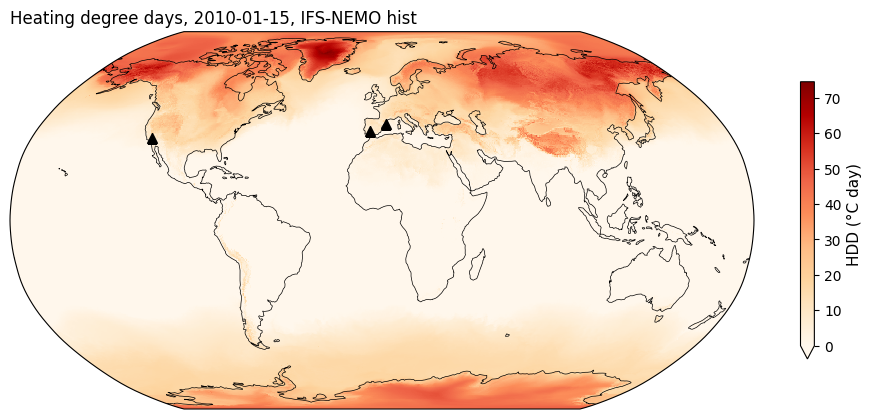

In [9]:
# the HDD of 15 January from the item found by the search above
href = next(a["href"] for k, a in item["assets"].items() if k.endswith("_15_T00_00_hdd.nc"))
p = item["properties"]
label = f"{p['internal_fdp:model'].upper()} {p['internal_fdp:experiment']}"

local_file = DATA_DIR / href.rsplit("/", 1)[-1]
if not local_file.exists():
    t0 = time.perf_counter()
    with requests.get(href, stream=True, headers=auth_headers, timeout=300) as resp:
        resp.raise_for_status()
        total_size = int(resp.headers.get("Content-Length", 0))
        with open(local_file.with_suffix(".part"), "wb") as f, tqdm(total=total_size, unit="B", unit_scale=True,
                                                                   desc=local_file.name) as bar:
            for chunk in resp.iter_content(chunk_size=1024 * 1024):
                f.write(chunk)
                bar.update(len(chunk))
    local_file.with_suffix(".part").rename(local_file)
    print(f"Downloaded {local_file.stat().st_size / 1e6:.0f} MB in {time.perf_counter() - t0:.0f} s")

with xr.open_dataset(local_file, engine="h5netcdf") as ds:
    hdd_global = ds["hdd"].isel(time=0).load()

g = hdd_global.isel(lat=slice(None, None, 10), lon=slice(None, None, 10))
g = g.assign_coords(lon=((g.lon + 180) % 360) - 180).sortby("lon")

fig, ax = plt.subplots(subplot_kw={"projection": ccrs.Robinson()}, figsize=(12, 6))
g.plot(ax=ax, transform=ccrs.PlateCarree(), cmap="OrRd", vmin=0,
       cbar_kwargs={"label": "HDD (°C day)", "shrink": 0.6})
ax.coastlines(linewidth=0.5)
for s in SITES.values():
    ax.plot(s["lon"], s["lat"], "k^", ms=7, transform=ccrs.PlateCarree())
ax.set_title(f"Heating degree days, {local_file.name[:10].replace('_', '-')}, {label}")
plt.show()

## Read only what you need

An asset URL answers with a redirect to a time-limited, signed link on the Data Lake's storage. That link supports
HTTP range requests, so `xarray` can open the file remotely and transfer only the bytes of the grid cells we select:
a few kilobytes for one location instead of hundreds of megabytes for the global file.

The helpers below
- find the items of a simulation for a period (`find_items`),
- open one asset remotely (`open_remote`),
- read the nearest grid cell of one location from one asset (`read_point`), or a small box around it (`read_region`),
- read one location from many assets in parallel and join them (`fetch_point_series`).

The files use longitudes 0..360, so the helpers convert the locations and return longitudes in -180..180.

In [10]:
def month_items(simulation, month):
    """The item(s) of one month, e.g. month="2036-01"."""
    p = pd.Period(month, "M")
    return find_items(simulation, f"{p.start_time:%Y-%m-%d}", f"{p.end_time:%Y-%m-%d}")


def find_items(simulation, start, end):
    """Items (one per month) of a simulation between two dates, following the search pages."""
    body = {"collections": [COLLECTION_ID], "limit": 100,
            "datetime": f"{start}T00:00:00Z/{end}T23:59:59Z"}
    found, url = [], SEARCH_URL
    while url:
        for attempt in range(5):                 # retry a dropped connection or a server error
            try:
                r = requests.post(url, json=body, headers=auth_headers, timeout=120)
                check_access(r)                  # HTTP 403: no access, stop with a clear message
                break
            except (requests.ConnectionError, requests.Timeout, requests.HTTPError):
                if attempt == 4:
                    raise
                time.sleep(2 ** attempt)
        page = r.json()
        found += [f for f in page["features"]
                  if all(str(f["properties"].get("internal_fdp:" + k)) == v for k, v in simulation.items())]
        nxt = next((l for l in page.get("links", []) if l.get("rel") == "next"), None)
        url, body = (nxt["href"], nxt.get("body", body)) if nxt else (None, None)
    return sorted(found, key=lambda f: f["properties"]["start_datetime"])


def open_remote(href, token):
    """Open one asset over HTTP without downloading it (only the metadata is read here)."""
    with requests.get(href, headers={"Authorization": f"Bearer {token}"},
                      allow_redirects=False, stream=True, timeout=120) as r:
        r.raise_for_status()
        url = r.headers["Location"]          # signed link; no token needed from here on
    f = fsspec.filesystem("http").open(url, block_size=2**16, cache_type="readahead")
    return xr.open_dataset(f, engine="h5netcdf")


def read_point(href, token, lat, lon):
    """The nearest grid cell of one location, from one asset; three attempts. If the file cannot be read (e.g. a file
    missing in the Data Lake, or a connection that keeps failing), the text of the last error is returned instead."""
    err = "unknown error"
    for attempt in range(3):
        try:
            with open_remote(href, token) as ds:
                pt = ds.sel(lat=lat, lon=lon % 360, method="nearest").load()
            return pt.squeeze("level", drop=True) if "level" in pt.dims else pt
        except Exception as e:
            err = f"{type(e).__name__}: {e}"[:300]
            time.sleep(2 ** attempt)
    return err


def read_points(hrefs, site, what):
    """read_point for many assets in parallel. Prints how many files could not be read, and stops with a clear
    message (with the first error) if none could be read."""
    if not hrefs:
        raise RuntimeError(f"No files found for {what}: the Data Lake has no item for this period.")
    refresh_token()
    got = Parallel(n_jobs=N_JOBS)(delayed(read_point)(h, access_token, site["lat"], site["lon"]) for h in hrefs)
    ok = [p for p in got if isinstance(p, xr.Dataset)]
    bad = [p for p in got if not isinstance(p, xr.Dataset)]
    if bad:
        print(f"{what}: {len(bad)} of {len(got)} files could not be read; first error: {bad[0]}")
    if not ok:
        raise RuntimeError(f"No files could be read for {what} ({len(got)} found, all failed). First error: "
                           f"{bad[0]}. Check your access (see Prerequisites) and that all packages are installed, "
                           "then run the cell again.")
    return ok


def read_region(href, token, lat, lon, half_width=MAP_HALF_WIDTH, time=None):
    """A box of +-half_width degrees around a location, from one asset (longitudes returned in -180..180).
    `time` reads one time step of a file with several (e.g. one day of a monthly file)."""
    for attempt in range(5):                 # retry a temporary error of the Data Lake (up to about 30 s)
        try:
            return _read_region(href, token, lat, lon, half_width, time)
        except Exception:
            if attempt == 4:
                raise
            time_module.sleep(2 ** attempt)


def _read_region(href, token, lat, lon, half_width, time):
    with open_remote(href, token) as ds:
        if time is not None:
            ds = ds.sel(time=[time])
        w, e = (lon - half_width) % 360, (lon + half_width) % 360
        box = ds.sel(lat=slice(lat - half_width, lat + half_width))
        if w <= e:
            box = box.sel(lon=slice(w, e))
        else:                                # box across 0 degrees longitude
            box = xr.concat([box.sel(lon=slice(w, None)), box.sel(lon=slice(None, e))], dim="lon")
        box = box.load()
    return box.assign_coords(lon=((box.lon + 180) % 360) - 180)


def asset_hrefs(items, suffix):
    """(month, href) of every asset whose name ends with `suffix`, over a list of items."""
    out = []
    for it in items:
        month = pd.Timestamp(it["properties"]["start_datetime"]).tz_convert(None)
        out += [(month, a["href"]) for k, a in sorted(it["assets"].items()) if k.endswith(suffix)]
    return out


def fetch_point_series(sector, simulation_name, suffix, periods=None):
    """One location (SITES[sector]) from every `suffix` asset of a simulation and period (default
    PERIODS), read in parallel and joined along time; kept in DATA_DIR, so a second run reads it from disk."""
    site = SITES[sector]
    y0, y1 = (periods or PERIODS)[simulation_name]
    tag = suffix.strip("_").removesuffix(".nc")
    path = DATA_DIR / f"{sector}_{tag}_{simulation_name}_{y0}-{y1}.nc"
    if path.exists():
        return xr.open_dataset(path, engine="h5netcdf")
    t0, parts, skipped, first_error = time.perf_counter(), [], [], None
    items = find_items(SIMULATIONS[simulation_name], f"{y0}-01-01", f"{y1}-12-31")
    hrefs = asset_hrefs(items, suffix)
    CHUNK = 1000                             # about 2 minutes of reading: a fresh token for each chunk
    with Parallel(n_jobs=N_JOBS) as parallel, tqdm(total=len(hrefs), desc=f"{simulation_name} {tag}") as bar:
        for i in range(0, len(hrefs), CHUNK):
            refresh_token()
            chunk = hrefs[i:i + CHUNK]
            got = parallel(delayed(read_point)(h, access_token, site["lat"], site["lon"]) for _, h in chunk)
            for (_, h), p in zip(chunk, got):
                if not isinstance(p, xr.Dataset):
                    skipped.append(h.rsplit("/", 1)[-1])
                    first_error = first_error or p
            got = [p if isinstance(p, xr.Dataset) else None for p in got]
            if "histogram" in suffix:        # monthly histograms: label each with its month
                got = [(p.squeeze("time", drop=True) if "time" in p.dims else p).expand_dims(time=[m])
                       if p is not None else None for (m, _), p in zip(chunk, got)]
            parts += [p for p in got if p is not None]
            bar.update(len(chunk))
    print(f"{len(hrefs)} files from {len(items)} months in {time.perf_counter() - t0:.0f} s")
    if skipped:                              # files that could not be read after three attempts
        print(f"  {len(skipped)} files could not be read and are left out: " + ", ".join(skipped[:10])
              + (" ..." if len(skipped) > 10 else "") + f"\n  first error: {first_error}")
    if not parts:
        raise RuntimeError(f"No files could be read for {simulation_name} {tag} ({len(hrefs)} found). First error: "
                           f"{first_error}. Check your access (see Prerequisites) and that all packages are "
                           "installed, then run the cell again.")
    out = xr.concat(parts, dim="time").sortby("time")
    out = out.sel(time=~out.get_index("time").duplicated())                   # files overlapping two items
    out = out.sel(time=slice(f"{y0}-01-01", f"{y1}-12-31"))
    out.to_netcdf(path, engine="h5netcdf")
    return out

### How long will it take?

Reading one location from one file takes about 1.6 s, dominated by the requests to the Data Lake, so the number of
files sets the time. With `N_JOBS = 16` files in parallel, a laptop reads about 10 daily files per second. A histogram
file is slower (about 1.5 files per second): its `bin` axis lies outside the grid, so one location needs about 30
separate reads.

| Section | Quick mode (5 + 5 years): files, time measured | Full mode (25 + 35 years): files, time estimated |
|---|---|---|
| Demand (HDD and CDD, one file per day each) | about 7,300, about 12 min | about 44,000, about 75 min |
| Wind (counts and edges of five histograms per month, plus the daily maxima) | about 1,200, about 13 min | about 7,200, about 80 min |
| Solar (PVP, one file per day) | about 3,650, about 6 min | about 22,000, about 40 min |

In the next release of the data, the daily indicators will be stored as one file per month: about 30 times fewer
files, which will make these reads several times faster (up to about 30 times, depending on how the files are
chunked).

The data transferred are of the order of 0.1 MB per file. Note also that a few months are missing in the Data Lake; they are skipped and shown as gaps.

### Small helpers for the statistics

`annual` and `monthly` aggregate daily values per year and per month. A month or year with missing days is left out
(`min_count`), so that missing months in the Data Lake do not bias the sums. `annual_cycle` gives, per calendar month,
the mean over the years and the range across years. `compare_to_variability` says in words whether the change between
the two periods is larger than the normal differences between years, i.e. whether the periods are long enough to see
it.
`plot_periods` and `plot_exceedance` draw the two periods side by side, as annual values and as the number of days per
year above a given daily value.

*Optional detail:* the normal differences between years are measured by the standard deviation of the annual values.
Averaging more years makes the period means more precise, so the change is compared with the uncertainty of the
difference of the two period means (the standard deviation of each period divided by the square root of its number of
years, combined). A change of more than twice that uncertainty is called a clear signal (about 95 % confidence), a
change of less than once that cannot be told apart from chance.

In [11]:
def monthly(da, how="sum"):
    n = da.time.dt.days_in_month.resample(time="MS").first()
    agg = da.resample(time="MS")
    out = agg.sum(min_count=1) if how == "sum" else agg.mean()
    return out.where(agg.count() == n)       # only complete months


def annual(da, how="sum"):
    m = monthly(da, how)
    agg = m.resample(time="YS")
    out = agg.sum(min_count=12) if how == "sum" else agg.mean()
    return out.where(agg.count() == 12)      # only complete years


def annual_cycle(monthly_values):
    g = monthly_values.groupby("time.month")
    return g.mean(), g.min(), g.max()


def plot_cycle(ax, series, label_unit):
    for name, m in series.items():
        mean, lo, hi = annual_cycle(m)
        years = m.time.dt.year
        ax.plot(mean.month, mean, color=COLOURS[name], marker="o",
                label=f"{name} {int(years.min())}–{int(years.max())}")
        ax.fill_between(mean.month, lo, hi, color=COLOURS[name], alpha=0.2)
    ax.set_xticks(range(1, 13), list("JFMAMJJASOND"))
    ax.set_ylabel(label_unit)
    ax.legend()


def print_cycle_change(monthly_values, name, unit, fmt):
    # highest and lowest month of each period, and the month with the largest change between the periods
    c = {n: m.groupby("time.month").mean() for n, m in monthly_values.items()}
    month = lambda k: pd.Timestamp(2000, int(k), 1).strftime("%B")
    for n, v in c.items():
        print(f"{name}, {n}: highest in {month(v.idxmax())} ({fmt.format(float(v.max()))} {unit}), "
              f"lowest in {month(v.idxmin())} ({fmt.format(float(v.min()))} {unit})".replace(" )", ")"))
    h, p = (c[n] for n in SIMULATIONS)
    d = p - h
    k = int(abs(d).idxmax())
    rel = f", {100 * float(d.sel(month=k) / h.sel(month=k)):+.0f} %" if float(h.sel(month=k)) else ""
    print(f"{name}: largest change in {month(k)}: {fmt.format(float(h.sel(month=k)))} -> "
          f"{fmt.format(float(p.sel(month=k)))} {unit}{rel}".replace(" ,", ","))


def compare_to_variability(annual_values, unit):
    # the change of the mean between the periods, against what the year-to-year differences could produce by
    # chance with periods of this length (uncertainty of the difference of the two period means)
    h, p = (annual_values[n].dropna("time") for n in SIMULATIONS)
    nh, np_ = h.sizes["time"], p.sizes["time"]
    change, spread = float(p.mean() - h.mean()), float(h.std(ddof=1))
    chance = float(np.sqrt(h.var(ddof=1) / nh + p.var(ddof=1) / np_))
    years = f"{nh} + {np_} complete years"
    length = min(PERIODS[n][1] - PERIODS[n][0] + 1 for n in SIMULATIONS)        # years in the shorter period
    longer = "; use 20-30 years per period" if length < 20 else ""
    if min(nh, np_) < length:
        years += " (years with a month missing in the Data Lake are left out)"
    if abs(change) > 2 * chance:
        verdict = (f"much larger than what the normal differences between years could produce by chance "
                   f"with {years}, so it is a clear signal")
    elif abs(change) > chance:
        verdict = f"larger than what chance usually produces, but not by enough to be sure with {years}{longer}"
    else:
        verdict = (f"not larger than what the normal differences between years can produce by chance, "
                   + (f"so {years} are not enough to tell{longer}" if longer else f"so there is no clear change over {years}"))
    print(f"change {change:+.3g} {unit} ({100 * change / float(h.mean()):+.1f} %): {verdict} "
          f"(normal year-to-year difference: about {spread:.3g} {unit})".replace(" )", ")"))


def plot_periods(ax, annual_values, unit, kind="bar", fmt="{:.0f}"):
    # annual values of the two periods next to each other (the decades between them are left out),
    # with the mean of each period; a year missing in the Data Lake is marked "n/a"
    ticks, labels, x0 = [], [], 0
    for name, a in annual_values.items():
        y0, y1 = PERIODS[name]
        years = np.arange(y0, y1 + 1)
        vals = pd.Series(a.values, index=a.time.dt.year.values).reindex(years)
        x = x0 + np.arange(years.size)
        if kind == "bar":
            ax.bar(x, vals, width=0.7, color=COLOURS[name], alpha=0.8, label=f"{name} {y0}–{y1}")
        else:
            ax.plot(x, vals, "o", ms=8, color=COLOURS[name], label=f"{name} {y0}–{y1}")
        mean = vals.mean()
        ax.hlines(mean, x[0] - 0.4, x[-1] + 0.4, color=COLOURS[name], lw=2.5)
        ax.annotate(f"mean {fmt.format(mean)}", (x.mean(), mean), xytext=(0, 5), textcoords="offset points",
                    ha="center", va="bottom", color=COLOURS[name], fontsize=10, fontweight="bold",
                    bbox=dict(fc="white", ec="none", alpha=0.7, pad=1))
        for xi in x[vals.isna().values]:
            ax.annotate("n/a" if years.size <= 10 else "×", (xi, 0), xycoords=("data", "axes fraction"), xytext=(0, 4),
                        textcoords="offset points", ha="center", color="grey", fontsize=8)
        step = 1 if years.size <= 10 else 5             # long periods: label every 5th year
        ticks += [xi for xi, y in zip(x, years) if (y - years[0]) % step == 0]
        labels += [str(y) for y in years if (y - years[0]) % step == 0]
        if x0 > 0:
            ax.axvline(x0 - 1.25, color="grey", lw=1, ls=(0, (2, 3)))
        x0 = x[-1] + 2.5
    ax.set_xticks(ticks, labels, fontsize=9)
    ax.grid(axis="x", visible=False)
    lo, hi = ax.get_ylim()
    ax.set_ylim(0 if kind == "bar" else lo, hi + 0.2 * (hi - (0 if kind == "bar" else lo)))   # room for the legend
    ax.set_ylabel(unit)
    ax.legend(loc="upper left", ncols=2)


def plot_exceedance(ax, daily_values, what):
    # days per year on which the daily value reaches at least x (x > 0): the distribution read as "how often"
    for name, da in daily_values.items():
        valid = da.dropna("time").values
        n_years = valid.size / 365.25
        v = np.sort(valid[valid > 0])[::-1]
        y0, y1 = PERIODS[name]
        ax.plot(v, np.arange(1, v.size + 1) / n_years, color=COLOURS[name], lw=2.2,
                label=f"{name} {y0}–{y1}" + (f": {v.size / n_years:.0f} days per year > 0" if v.size < valid.size else ""))
    ax.set_xlabel(what)
    ax.set_ylabel("days per year at or above this value")
    ax.set_ylim(bottom=0)
    ax.set_xlim(left=0)
    ax.legend()

## Energy demand: heating and cooling degree days in Barcelona

**In practice:** heating degree days (HDD) and cooling degree days (CDD) are a simple measure of how much energy
buildings need for heating and for air conditioning. A day that is 5 °C colder than the comfort threshold counts
5 HDD; summed over a year, twice the degree days means roughly twice the heating (or cooling) energy for the same
buildings. Utilities and system operators use them to explain and plan electricity and gas demand.

They are computed from the daily mean, maximum and minimum 2 m temperature relative to a base temperature: 15.5 °C for
HDD and 22 °C for CDD [1].

[1] https://doi.org/10.1002/joc.3959

### (a) Files used

`YYYY_MM_DD_T00_00_hdd.nc` and `YYYY_MM_DD_T00_00_cdd.nc`: one file per day, each a global field of that day.

### (b) One month of daily values

**Plot only.** The daily values of one January (HDD) and one July (CDD), in a year of each period: 31 files per month,
four months in all, read in a few seconds.

*What to look for:* how much the need changes from day to day, and how the same month differs between the two
periods. The monthly totals in the corner are what matters for energy planning. Here the January of the projection
year happens to be colder than that of the historical year: a single month says little about a change in climate,
which is why the next step compares whole periods.

Nearest grid cell: 41.375° N, 2.150° E


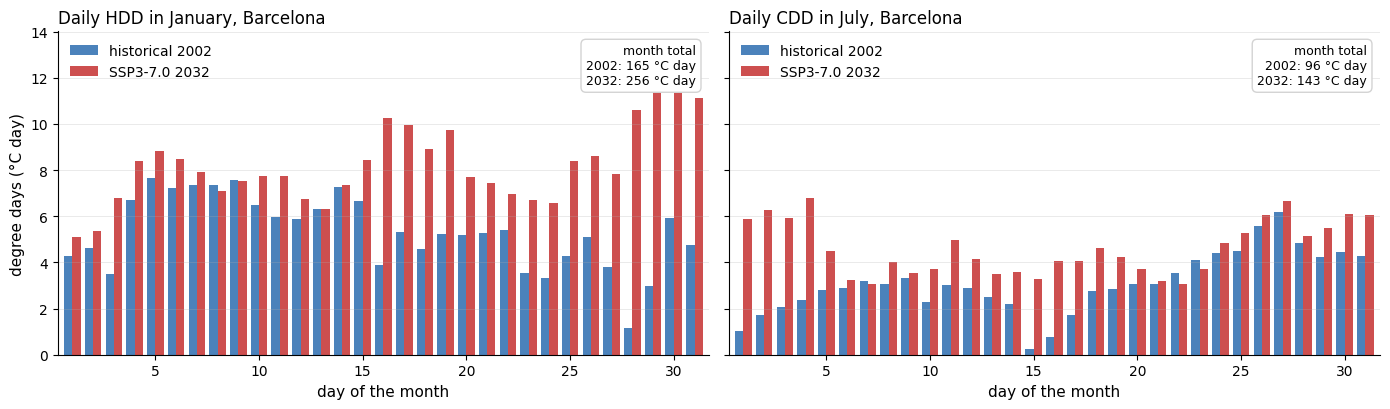

In [12]:
site = SITES["demand"]
years = {"historical": sum(HIST_YEARS) // 2, "SSP3-7.0": sum(PROJ_YEARS) // 2}   # the middle year of each period
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, (ind, mm) in zip(axes, [("hdd", 1), ("cdd", 7)]):
    totals = []
    for k, (name, year) in enumerate(years.items()):
        its = month_items(SIMULATIONS[name], f"{year}-{mm:02d}")
        hrefs = [h for _, h in asset_hrefs(its, f"_{ind}.nc")]
        pts = read_points(hrefs, site, f"{ind.upper()} {year}-{mm:02d}")
        s = xr.concat(pts, "time")[ind].squeeze()
        s = s.sel(time=s.time.dt.month == mm)
        ax.bar(s.time.dt.day + (k - 0.5) * 0.4, s, width=0.4, color=COLOURS[name], alpha=0.85,
               label=f"{name} {year}")
        totals.append(f"{year}: {float(s.sum()):.0f} °C day")
    ax.text(0.98, 0.96, "month total\n" + "\n".join(totals), transform=ax.transAxes, ha="right", va="top",
            fontsize=9, bbox=dict(fc="white", ec="lightgrey", boxstyle="round,pad=0.4"))
    ax.set_title(f"Daily {ind.upper()} in {pd.Timestamp(2000, mm, 1):%B}, {site['name']}")
    ax.set_xlabel("day of the month")
    ax.set_xlim(0.3, 31.7)
    ax.grid(axis="x", visible=False)
    ax.legend(loc="upper left")
axes[0].set_ylabel("degree days (°C day)")
print(f"Nearest grid cell: {float(s.lat):.3f}° N, {float(s.lon) - 360 * (float(s.lon) > 180):.3f}° E")
plt.tight_layout()
plt.show()

### (c) The two periods: historical against projection

**Computation:** annual sums of the daily values. This is the longest step of the notebook (about 7,300 files in the
quick mode, about 44,000 in the full mode); the result is kept on disk.

*What to look for:* the gap between the two mean lines against how much the bars differ within each period. The
printed lines below the figure say in words whether the periods are long enough.

In [13]:
demand = {ind: {name: fetch_point_series("demand", name, f"_{ind}.nc")[ind].squeeze()
                for name in SIMULATIONS}
          for ind in ("hdd", "cdd")}

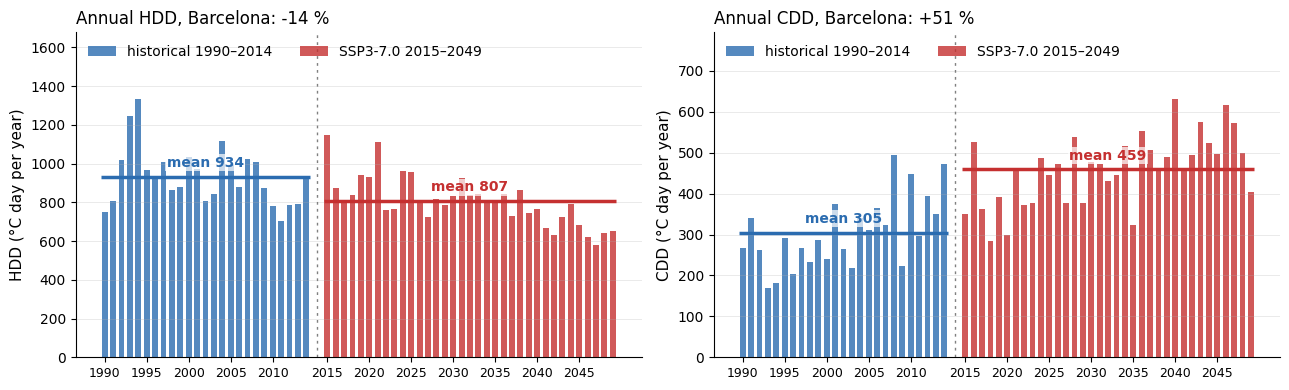

HDD: 

change -127 °C day (-13.6 %): much larger than what the normal differences between years could produce by chance with 25 + 35 complete years, so it is a clear signal (normal year-to-year difference: about 150 °C day)
CDD: 

change +154 °C day (+50.6 %): much larger than what the normal differences between years could produce by chance with 25 + 35 complete years, so it is a clear signal (normal year-to-year difference: about 87 °C day)


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, ind in zip(axes, ("hdd", "cdd")):
    plot_periods(ax, {n: annual(da) for n, da in demand[ind].items()}, f"{ind.upper()} (°C day per year)")
    h, p = (float(annual(demand[ind][n]).mean()) for n in SIMULATIONS)
    ax.set_title(f"Annual {ind.upper()}, {site['name']}: {100 * (p - h) / h:+.0f} %")
plt.tight_layout()
plt.show()
for ind in ("hdd", "cdd"):
    print(ind.upper(), end=": ")
    compare_to_variability({n: annual(da) for n, da in demand[ind].items()}, "°C day")

**Result:** between 1990–2014 and 2015–2049, the cooling need in Barcelona rises by about 50 % and the heating need
falls by about 14 %. Both changes are much larger than the normal differences between years, so both are clear
signals: air-conditioning demand will grow and heating demand will shrink. With only five years per period, the
heating decrease would not have been clear; Appendix A explains why conclusions need the whole period.

### (d) Annual cycle

**Computation:** monthly sums, then their mean over the years for each calendar month (line) and the range across
years (shading).

*What to look for:* in which months the change happens. Where the shaded ranges of the two periods hardly overlap,
the change is larger than the normal differences between years.

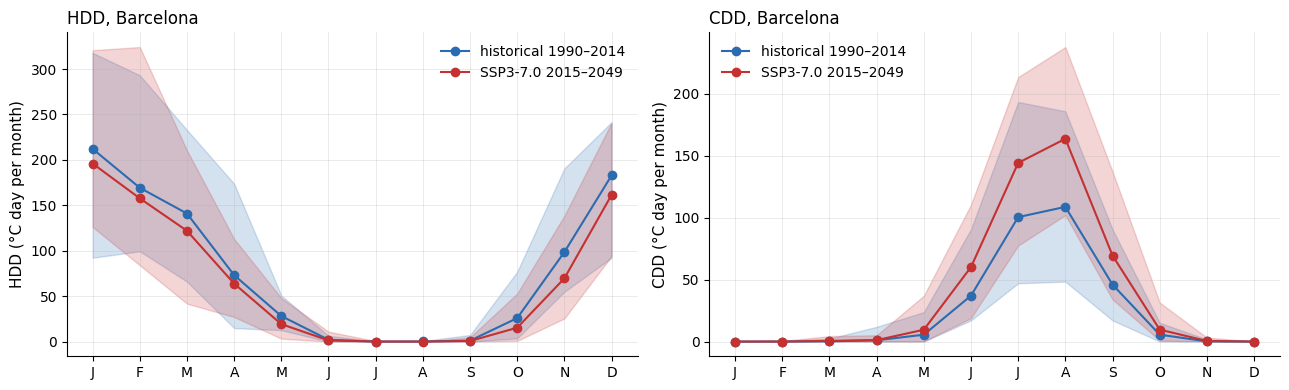

HDD, historical: highest in January (212 °C day per month), lowest in July (0 °C day per month)
HDD, SSP3-7.0: highest in January (196 °C day per month), lowest in August (0 °C day per month)
HDD: largest change in November: 98 -> 70 °C day per month, -29 %


CDD, historical: highest in August (109 °C day per month), lowest in December (0 °C day per month)
CDD, SSP3-7.0: highest in August (164 °C day per month), lowest in January (0 °C day per month)
CDD: largest change in August: 109 -> 164 °C day per month, +51 %


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, ind in zip(axes, ("hdd", "cdd")):
    plot_cycle(ax, {n: monthly(da) for n, da in demand[ind].items()}, f"{ind.upper()} (°C day per month)")
    ax.set_title(f"{ind.upper()}, {site['name']}")
plt.tight_layout()
plt.show()
for ind in ("hdd", "cdd"):
    print_cycle_change({n: monthly(da) for n, da in demand[ind].items()}, ind.upper(), "°C day per month", "{:.0f}")

**Result:** cooling demand grows in every summer month, most in July and August, and the cooling season starts
earlier and ends later: June and September grow by half or more. Heating demand falls in every month with heating,
most strongly (in relative terms) in autumn, in October and November.

### (e) Distribution of daily values

**Computation:** for every daily value x, the number of days per year on which the daily value is at least x. Each
curve starts on the left at the number of days per year with any heating (or cooling) need at all, i.e. a daily value
above zero; on the other days of the year no heating (or cooling) is needed. Further right are the days with a large
need. The vertical distance between the two curves is the change in days per year.

*What to look for:* whether the change comes from more days with some need or from more days with a large need,
which matters for peak demand.

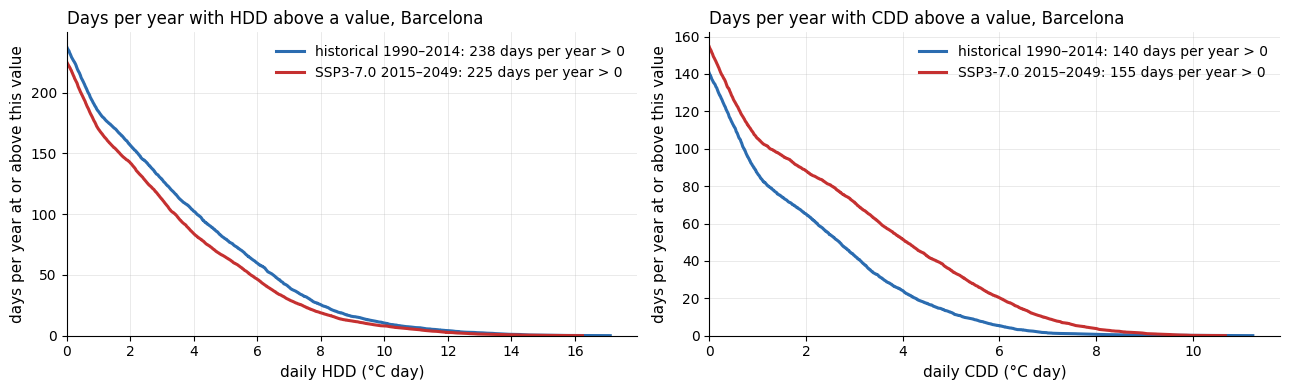

days per year with HDD >= 5 °C day: historical 80, SSP3-7.0 65
days per year with CDD >= 5 °C day: historical 12, SSP3-7.0 35


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, ind in zip(axes, ("hdd", "cdd")):
    plot_exceedance(ax, demand[ind], f"daily {ind.upper()} (°C day)")
    ax.set_title(f"Days per year with {ind.upper()} above a value, {site['name']}")
plt.tight_layout()
plt.show()
for ind, x in (("hdd", 5), ("cdd", 5)):
    days = {n: float((da >= x).sum()) / (da.sizes["time"] / 365.25) for n, da in demand[ind].items()}
    print(f"days per year with {ind.upper()} >= {x} °C day: " + ", ".join(f"{n} {d:.0f}" for n, d in days.items()))

**Result:** the number of days with a large cooling need (CDD of 5 or more, i.e. a daily mean temperature of about
27 °C or more) roughly triples, from about 12 to about 35 per year. Hot days, which drive the peaks of electricity
demand, increase far more than the annual total. Days with a large heating need (HDD of 5 or more) fall from about 80
to about 65 per year.

### (f) Map of the surroundings

**Plot only.** HDD of one winter day in a box of ±3° around Barcelona (`MAP_HALF_WIDTH`) at the native resolution:
each pixel is one grid cell of 0.05° (about 5 km), 120 × 120 cells in all. The contrast between the coast, the
inland plains and the Pyrenees is resolved.

*What to look for:* how much the value changes over a few grid cells. A single location stands for its grid cell
only; nearby inland or mountain sites can have a very different need.

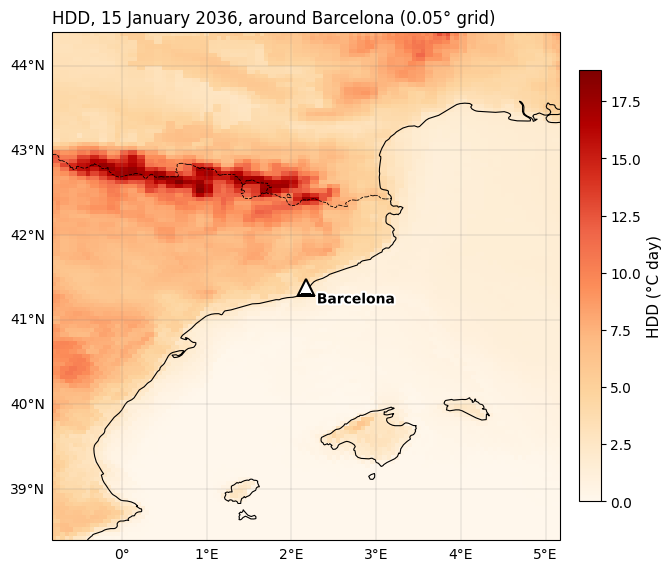

In [17]:
def plot_region(box, var, site, title, cmap, label, ax=None, **kw):
    if ax is None:
        fig, ax = plt.subplots(subplot_kw={"projection": ccrs.PlateCarree()}, figsize=(8, 7))
    m = box[var].squeeze().plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, add_colorbar=False, **kw)
    plt.colorbar(m, ax=ax, label=label, shrink=0.8, pad=0.03)
    ax.add_feature(cfeature.COASTLINE.with_scale("10m"), linewidth=0.8)
    ax.add_feature(cfeature.BORDERS.with_scale("10m"), linewidth=0.6, linestyle="--")
    ax.plot(site["lon"], site["lat"], "^", ms=11, mfc="white", mec="black", mew=1.5, transform=ccrs.PlateCarree())
    ax.annotate(site["name"], (site["lon"], site["lat"]), xytext=(8, -12), textcoords="offset points",
                fontsize=10, fontweight="bold", path_effects=[pe.withStroke(linewidth=3, foreground="white")])
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="grey", alpha=0.6)
    gl.right_labels = False
    gl.top_labels = False
    ax.set_title(title, loc="left")
    return ax


day_items = month_items(SIMULATIONS["SSP3-7.0"], "2036-01")
href = next(a["href"] for k, a in day_items[0]["assets"].items() if k.endswith("_15_T00_00_hdd.nc"))
box = read_region(href, access_token, site["lat"], site["lon"])
plot_region(box, "hdd", site, f"HDD, 15 January 2036, around {site['name']} (0.05° grid)", "OrRd", "HDD (°C day)")
plt.show()

## Wind energy: Alta Wind Energy Center, Tehachapi Pass

The Alta Wind Energy Center lies in the Tehachapi Pass, California, where the flow is channelled between mountain
ranges: a good test of what a 0.05° (about 5 km) grid resolves.

**In practice:** the **capacity factor (CF)** is the share of a turbine's rated power that it actually produces,
averaged over time: a CF of 0.3 means a 3 MW turbine produces on average 0.9 MW. It depends on the wind speed at hub
height (here 100 m) and on the turbine's power curve: no production below about 3 m s⁻¹ (cut-in), full power from
about 12 m s⁻¹, and shut-down above 25 m s⁻¹ (cut-out). The **IEC classes** are turbine types designed for different
sites: class I for strong winds, II for medium, III for weak winds (larger rotor for the same generator), and S for
special designs, here offshore turbines.

### (a) Files used

- `YYYY_MM_01_to_YYYY_MM_DD_ws_timestep_60_daily_max.nc`: one file per month with the daily maximum of the hourly
  100 m wind speed (`ws`) and its time (`timings`).
- `YYYY_MM_ws_timestep_60_monthly_histogram_bin_counts.nc` and `..._bin_edges.nc`: the histogram of all hourly 100 m
  wind speeds of the month. The bin edges differ from cell to cell and month to month, so the counts are always read
  together with their edges.
- `YYYY_MM_cf_<class>_timestep_60_monthly_histogram_bin_counts.nc` and `..._bin_edges.nc`: the same for the hourly
  capacity factor of a turbine of IEC class I, II, III or S.

The histograms keep the hourly information in a compact form: the hourly series themselves are not stored.

### (b) One month of daily values

**Plot only.** One file holds 31 days. In the current release these 31-day windows are not aligned with the calendar
months: the file of the January 2036 item covers 26 January – 25 February 2036 (see its name). The dates are
therefore taken from the file, not from the item.

*What to look for:* windy spells of a few days separated by calm days; the colour shows the hour of the daily
maximum (UTC; local time in California is UTC − 8 h).

days in the file: 26 January – 25 February 2036


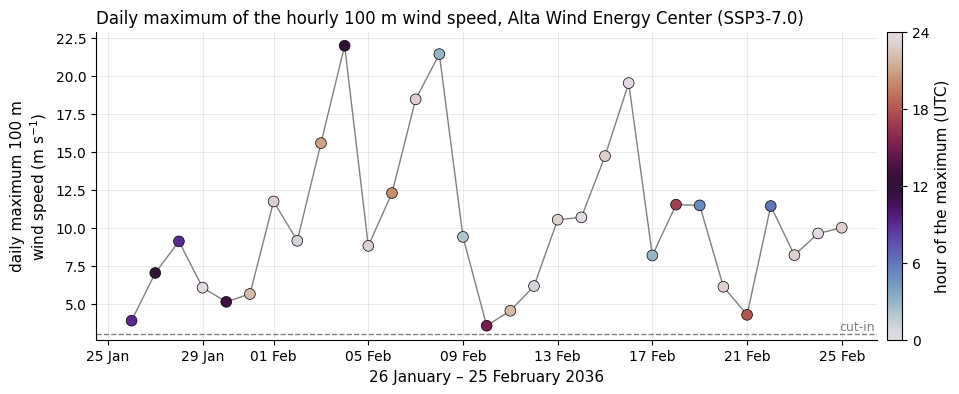

In [18]:
site = SITES["wind"]
its = month_items(SIMULATIONS["SSP3-7.0"], "2036-01")
_, href = asset_hrefs(its, "_ws_timestep_60_daily_max.nc")[0]
refresh_token()
ws_month = read_point(href, access_token, site["lat"], site["lon"])
if not isinstance(ws_month, xr.Dataset):
    raise RuntimeError(f"The daily-maximum file could not be read: {ws_month}. Check your access and packages.")
period = f"{pd.Timestamp(ws_month.time.values[0]):%d %B} – {pd.Timestamp(ws_month.time.values[-1]):%d %B %Y}"
print("days in the file:", period)

ws = ws_month["ws"].squeeze()
hour = pd.to_datetime(ws_month["timings"].squeeze().values).hour
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(ws.time, ws, color="grey", lw=1, zorder=1)
sc = ax.scatter(ws.time, ws, c=hour, cmap="twilight", vmin=0, vmax=24, s=60, edgecolor="black",
                linewidth=0.5, zorder=2)
plt.colorbar(sc, ax=ax, label="hour of the maximum (UTC)", ticks=range(0, 25, 6), pad=0.01)
for x, lab in ((3, "cut-in"), (25, "cut-out")):
    if ax.get_ylim()[0] < x < ax.get_ylim()[1]:
        ax.axhline(x, color="grey", ls="--", lw=1)
        ax.annotate(lab, (1, x), xycoords=("axes fraction", "data"), xytext=(-2, 3), textcoords="offset points",
                    ha="right", color="grey", fontsize=9)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_xlabel(period)
ax.set_ylabel("daily maximum 100 m\nwind speed (m s$^{-1}$)")
ax.set_title(f"Daily maximum of the hourly 100 m wind speed, {site['name']} (SSP3-7.0)")
plt.show()

### (c) Read the histograms for both periods

About 1,200 files in the quick mode (about 13 minutes), about 7,200 in the full mode.

**Computation:** to combine months whose bin edges differ, each month's counts are placed at their bin centres
and binned again on fixed bins (`common_bins`). The mean is taken from the bin centres too (`hist_mean`).

In [19]:
WIND_VARS = {"ws": "_ws_timestep_60_monthly_histogram_bin_", "cf_i": "_cf_i_timestep_60_monthly_histogram_bin_",
             "cf_ii": "_cf_ii_timestep_60_monthly_histogram_bin_", "cf_iii": "_cf_iii_timestep_60_monthly_histogram_bin_",
             "cf_s": "_cf_s_timestep_60_monthly_histogram_bin_"}

def binned(ds):
    """The histogram variable of a file (the one with a bin dimension), as (time, bin)."""
    da = next(v for v in ds.data_vars.values() if any(d.startswith("bin") for d in v.dims))
    return da.transpose("time", ...)


hist = {}
for var, stem in WIND_VARS.items():
    for name in SIMULATIONS:
        c = fetch_point_series("wind", name, stem + "counts.nc")
        e = fetch_point_series("wind", name, stem + "edges.nc")
        hist[var, name] = xr.align(binned(c), binned(e), join="inner")   # months with both counts and edges


def centres(counts, edges):
    """Bin centres of each month's own bins, aligned with the counts."""
    ed = edges.values
    return 0.5 * (ed[:, :-1] + ed[:, 1:])[:, : counts.shape[1]]


def hist_mean(counts, edges):
    """Monthly mean from the histogram (bin-centre approximation)."""
    x = centres(counts, edges)
    c = np.nan_to_num(counts.values)
    return xr.DataArray((c * x).sum(1) / c.sum(1), coords={"time": counts.time})


def common_bins(counts, edges, bins):
    """All months together on fixed bins, normalised to a probability density."""
    x, c = centres(counts, edges).ravel(), np.nan_to_num(counts.values).ravel()
    ok = np.isfinite(x)
    dens, _ = np.histogram(x[ok], bins=bins, weights=c[ok], density=True)
    return dens

**Computation:** annual mean 100 m wind speed from the monthly histograms, historical against projection.

*What to look for:* whether the two period means differ by more than the years within a period. A year with a
missing month in the Data Lake is marked n/a.

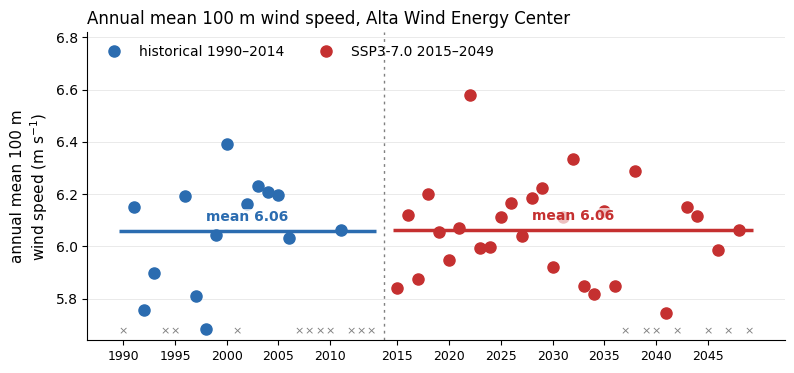

change +0.00442 m s-1 (+0.1 %): not larger than what the normal differences between years can produce by chance, so there is no clear change over 14 + 28 complete years (years with a month missing in the Data Lake are left out) (normal year-to-year difference: about 0.203 m s-1)


In [20]:
annual_ws = {}
for name in SIMULATIONS:
    m = hist_mean(*hist["ws", name])
    annual_ws[name] = m.resample(time="YS").mean().where(m.resample(time="YS").count() == 12)
fig, ax = plt.subplots(figsize=(9, 4))
plot_periods(ax, annual_ws, "annual mean 100 m\nwind speed (m s$^{-1}$)", kind="dot", fmt="{:.2f}")
ax.set_title(f"Annual mean 100 m wind speed, {site['name']}")
plt.show()
compare_to_variability(annual_ws, "m s-1")

**Result:** the mean wind speed does not change (+0.1 %), much less than the normal differences between years. The
wind resource at this site is stable in this simulation.

Several historical months are missing in the Data Lake for the wind histograms, so only years with all twelve months
are averaged (14 historical and 28 projection years); years with a missing month are marked ×.

### (d) Annual cycle

**Computation:** monthly means from the histograms, then the mean and range across years per calendar month.

*What to look for:* the windy season (spring and early summer at this site) and whether the projection shifts it.

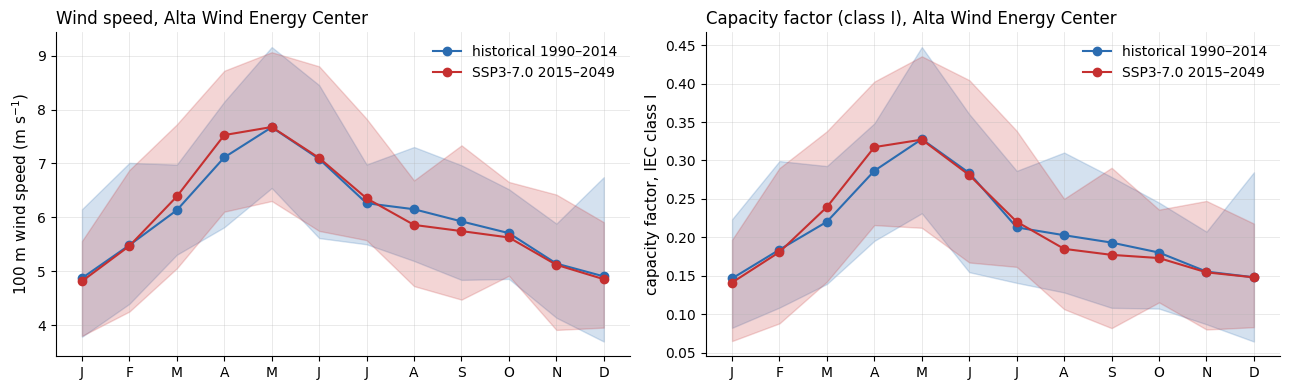

Wind speed, historical: highest in May (7.7 m s-1), lowest in January (4.9 m s-1)
Wind speed, SSP3-7.0: highest in May (7.7 m s-1), lowest in January (4.8 m s-1)
Wind speed: largest change in April: 7.1 -> 7.5 m s-1, +6 %


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_cycle(axes[0], {n: hist_mean(*hist["ws", n]) for n in SIMULATIONS}, "100 m wind speed (m s$^{-1}$)")
axes[0].set_title(f"Wind speed, {site['name']}")
plot_cycle(axes[1], {n: hist_mean(*hist["cf_i", n]) for n in SIMULATIONS}, "capacity factor, IEC class I")
axes[1].set_title(f"Capacity factor (class I), {site['name']}")
plt.tight_layout()
plt.show()
print_cycle_change({n: hist_mean(*hist["ws", n]) for n in SIMULATIONS}, "Wind speed", "m s-1", "{:.1f}")

**Result:** the windy season is spring, with the strongest monthly mean wind in May and the weakest in December and
January. The cycle is practically the same in both periods; the small differences, slightly windier in April and
slightly calmer in late summer, are within the normal differences between years shown by the shading.

### (e) Distributions: wind speed and the choice of turbine

**Computation:** all hourly values of each period, from the monthly histograms on fixed bins. The capacity factor of
the four turbine classes, from the same wind, shows how the expected production depends on the choice of turbine.

*What to look for:* left, the share of hours below cut-in, when no turbine produces. Right, the duration curve: for
each capacity factor, the share of hours the turbine reaches at least that output; the further up and right the curve,
the more energy. Here the class III turbine (built for weak winds) has the highest capacity factor: its larger rotor
reaches full power at lower wind speeds, which are frequent at this site.

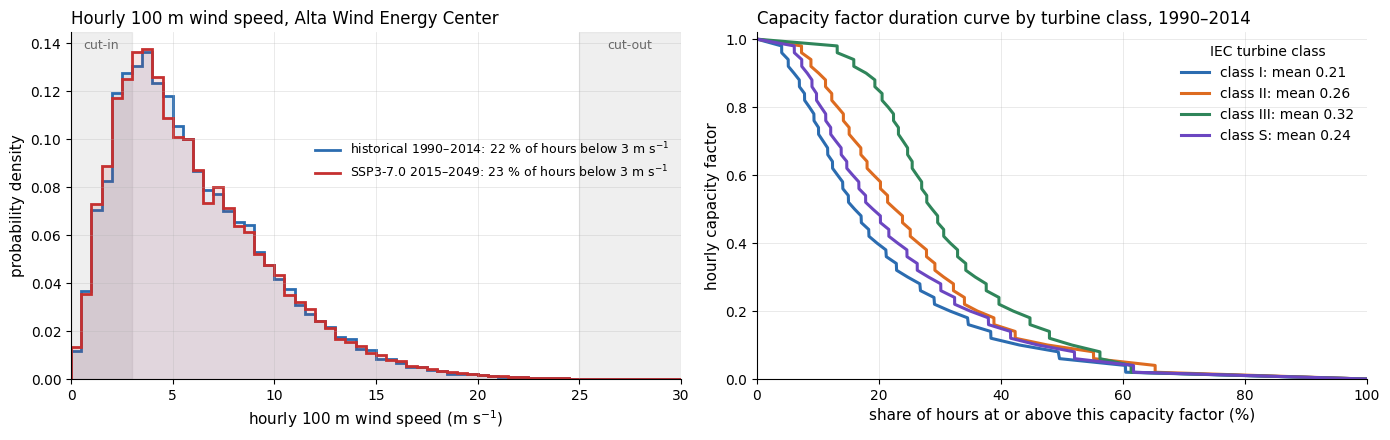

In [22]:
ws_bins = np.arange(0, 30.5, 0.5)
cf_bins = np.linspace(0, 1, 51)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ax = axes[0]
ax.axvspan(0, 3, color="grey", alpha=0.12)
ax.axvspan(25, 30, color="grey", alpha=0.12)
for name in SIMULATIONS:
    d = common_bins(*hist["ws", name], ws_bins)
    below = 100 * (d * np.diff(ws_bins))[ws_bins[:-1] < 3].sum()
    y0, y1 = PERIODS[name]
    ax.stairs(d, ws_bins, color=COLOURS[name], lw=2, label=f"{name} {y0}–{y1}: {below:.0f} % of hours below 3 m s$^{{-1}}$")
    ax.stairs(d, ws_bins, color=COLOURS[name], alpha=0.12, fill=True)
ax.annotate("cut-in", (1.5, 0.98), xycoords=("data", "axes fraction"), ha="center", va="top", fontsize=9,
            color="dimgrey")
ax.annotate("cut-out", (27.5, 0.98), xycoords=("data", "axes fraction"), ha="center", va="top", fontsize=9,
            color="dimgrey")
ax.set_xlim(0, 30)
ax.set_xlabel("hourly 100 m wind speed (m s$^{-1}$)")
ax.set_ylabel("probability density")
ax.set_title(f"Hourly 100 m wind speed, {site['name']}")
ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.72), fontsize=9)

ax = axes[1]
for var, col in zip(["cf_i", "cf_ii", "cf_iii", "cf_s"], ["#2b6cb0", "#dd6b20", "#2f855a", "#6b46c1"]):
    d = common_bins(*hist[var, "historical"], cf_bins)
    exceed = np.concatenate([[1.0], 1 - np.cumsum(d * np.diff(cf_bins))]).clip(0, 1)   # share of hours with CF >= x
    mean = float(hist_mean(*hist[var, "historical"]).mean())
    ax.plot(100 * exceed, cf_bins, color=col, lw=2.2, label=f"class {var[3:].upper()}: mean {mean:.2f}")
ax.set_xlabel("share of hours at or above this capacity factor (%)")
ax.set_ylabel("hourly capacity factor")
ax.set_xlim(0, 100)
ax.set_ylim(0, 1.02)
ax.set_title(f"Capacity factor duration curve by turbine class, {HIST_YEARS[0]}–{HIST_YEARS[1]}")
ax.legend(title="IEC turbine class")
plt.tight_layout()
plt.show()

**Result:** the wind distribution hardly changes between the periods (about 22–23 % of hours below cut-in in both),
so the expected production does not either. The choice of turbine matters far more: with the same wind, the mean
capacity factor ranges from about 0.21 (class I) to about 0.32 (class III).

### (f) Map of the surroundings

**Plot only.** Daily maximum 100 m wind speed in a box of ±3° around the wind farm on the windiest day of the file
at the farm. The monthly daily-maximum file holds all 31 days without chunking, so only the day needed is read: a few
seconds, against about two minutes for the whole month of the box.

*What to look for:* the strong wind channelled through the pass and over the sea, next to calm valleys only a few
grid cells away: the exact position of a wind farm matters at this resolution.

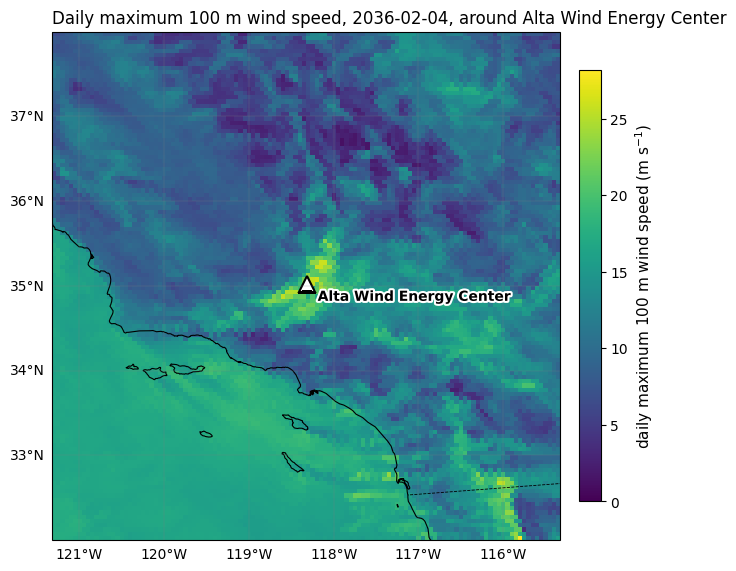

In [23]:
day = ws.time.values[int(ws.argmax("time"))]          # the windiest day of the file at the wind farm
box = read_region(href, access_token, site["lat"], site["lon"], time=day)
plot_region(box, "ws", site, f"Daily maximum 100 m wind speed, {str(box.time.values[0])[:10]}, around {site['name']}",
            "viridis", "daily maximum 100 m wind speed (m s$^{-1}$)", vmin=0)
plt.show()

**Optional: animation.** The same box for every day of the file: 31 one-day reads in parallel.

In [24]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

def read_day(t):
    try:
        return read_region(href, access_token, site["lat"], site["lon"], time=t)
    except Exception:                        # a day that cannot be read is left out of the animation
        return None


refresh_token()
days = [d for d in Parallel(n_jobs=N_JOBS)(delayed(read_day)(t) for t in ws.time.values) if d is not None]
if not days:
    raise RuntimeError("No day of the file could be read for the animation; check your access and run it again.")
month_box = xr.concat(days, "time")["ws"].squeeze()

fig, ax = plt.subplots(subplot_kw={"projection": ccrs.PlateCarree()}, figsize=(7, 6))
mesh = ax.pcolormesh(month_box.lon, month_box.lat, month_box.isel(time=0), vmin=0, vmax=float(month_box.max()),
                     cmap="viridis", transform=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE.with_scale("10m"), linewidth=0.8)
ax.add_feature(cfeature.STATES.with_scale("10m"), linewidth=0.4, linestyle="--")
ax.plot(site["lon"], site["lat"], "^", ms=11, mfc="white", mec="black", mew=1.5, transform=ccrs.PlateCarree())
plt.colorbar(mesh, ax=ax, label="daily maximum 100 m wind speed (m s$^{-1}$)", shrink=0.8)


def frame(i):
    mesh.set_array(month_box.isel(time=i).values.ravel())
    ax.set_title(f"{site['name']}, {str(month_box.time.values[i])[:10]}", loc="left")
    return (mesh,)


anim = FuncAnimation(fig, frame, frames=month_box.sizes["time"], interval=300)
plt.close(fig)
HTML(anim.to_jshtml())

## Solar energy: Núñez de Balboa PV plant

**In practice:** the photovoltaic potential (PVP) says how well PV panels would perform on a day: the expected output
relative to the rated capacity, like a capacity factor for solar. It grows with solar radiation and drops slightly
when the panels get hot (high air temperature, little wind to cool them). It is computed from the daily surface solar
radiation, 2 m temperature and 10 m wind speed.

### (a) Files used

`YYYY_MM_DD_T00_00_pvp.nc`: one file per day.

### (b) One month of daily values

**Plot only.** January and July of one year.

*What to look for:* summer days are steady and high; winter days are lower and vary with cloud.

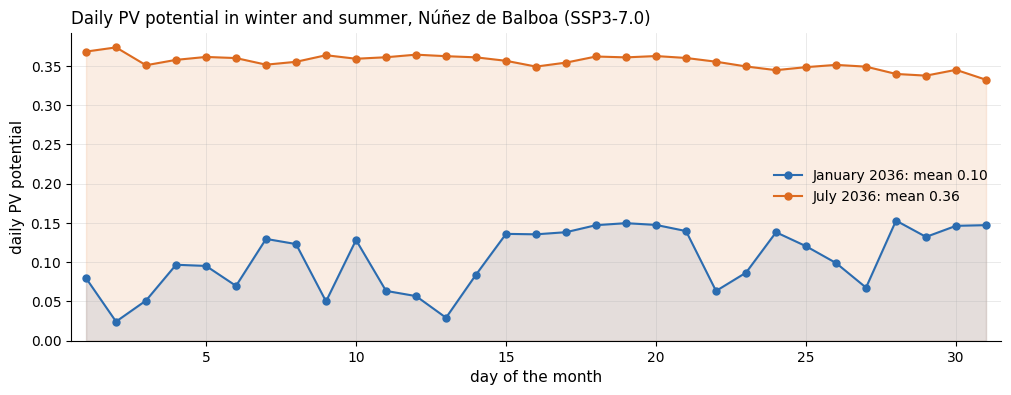

In [25]:
site = SITES["solar"]
fig, ax = plt.subplots(figsize=(12, 4))
for month, col in [("2036-01", "#2b6cb0"), ("2036-07", "#dd6b20")]:
    its = month_items(SIMULATIONS["SSP3-7.0"], month)
    pts = read_points([h for _, h in asset_hrefs(its, "_pvp.nc")], site, f"PV {month}")
    s = xr.concat(pts, "time")["pvp"].squeeze()
    ax.plot(s.time.dt.day, s, "o-", color=col, ms=5, label=f"{pd.Timestamp(month):%B %Y}: mean {float(s.mean()):.2f}")
    ax.fill_between(s.time.dt.day, 0, s, color=col, alpha=0.12)
ax.set_xlabel("day of the month")
ax.set_ylabel("daily PV potential")
ax.set_xlim(0.5, 31.5)
ax.set_ylim(bottom=0)
ax.set_title(f"Daily PV potential in winter and summer, {site['name']} (SSP3-7.0)")
ax.legend(loc="center right")
plt.show()

### (c) The two periods

**Computation:** annual means of the daily values (about 3,650 files in the quick mode, about 22,000 in the full mode).

*What to look for:* the vertical scale is very narrow, so small differences look large; the printed line says
whether the change is meaningful.

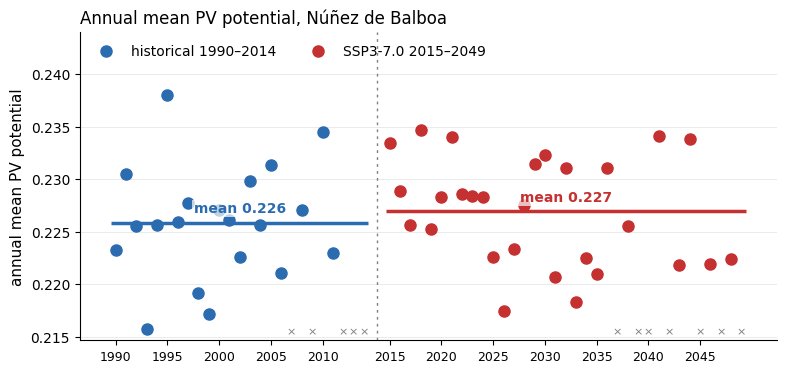

change +0.0011  (+0.5 %): not larger than what the normal differences between years can produce by chance, so there is no clear change over 20 + 28 complete years (years with a month missing in the Data Lake are left out) (normal year-to-year difference: about 0.00546)


In [26]:
pvp = {name: fetch_point_series("solar", name, "_pvp.nc")["pvp"].squeeze() for name in SIMULATIONS}

fig, ax = plt.subplots(figsize=(9, 4))
plot_periods(ax, {n: annual(da, how="mean") for n, da in pvp.items()}, "annual mean PV potential", kind="dot",
             fmt="{:.3f}")
ax.set_title(f"Annual mean PV potential, {site['name']}")
plt.show()
compare_to_variability({n: annual(da, how="mean") for n, da in pvp.items()}, "")

**Result:** the annual PV potential is practically unchanged (+0.5 %), well within the normal differences between
years. The solar resource at this site is stable in this simulation.

### (d) Annual cycle

**Computation:** monthly means, then the mean and range across years per calendar month.

*What to look for:* whether any season changes, even if the annual mean does not.

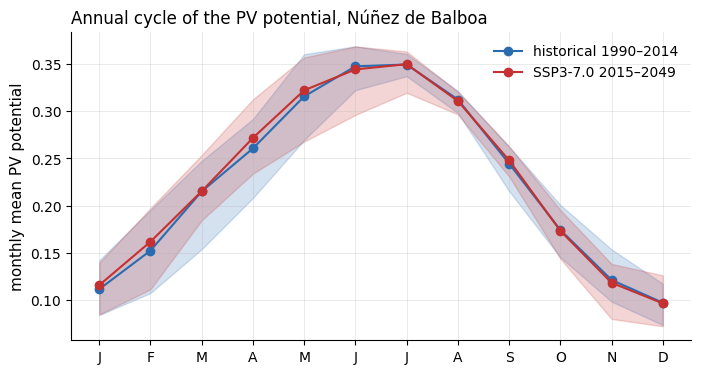

PV potential, historical: highest in July (0.349), lowest in December (0.097)
PV potential, SSP3-7.0: highest in July (0.350), lowest in December (0.097)
PV potential: largest change in April: 0.261 -> 0.272, +4 %


In [27]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_cycle(ax, {n: monthly(da, how="mean") for n, da in pvp.items()}, "monthly mean PV potential")
ax.set_title(f"Annual cycle of the PV potential, {site['name']}")
plt.show()
print_cycle_change({n: monthly(da, how="mean") for n, da in pvp.items()}, "PV potential", "", "{:.3f}")

**Result:** the PV potential is highest in June and July and lowest in December, more than three times lower. The
cycle is the same in both periods: no season changes noticeably.

### (e) Distribution of daily values

**Computation:** the number of days per year with a daily PV potential of at least x, as for the degree days. The
flat part around 0.12 and the steep part around 0.35 are the winter and summer days.

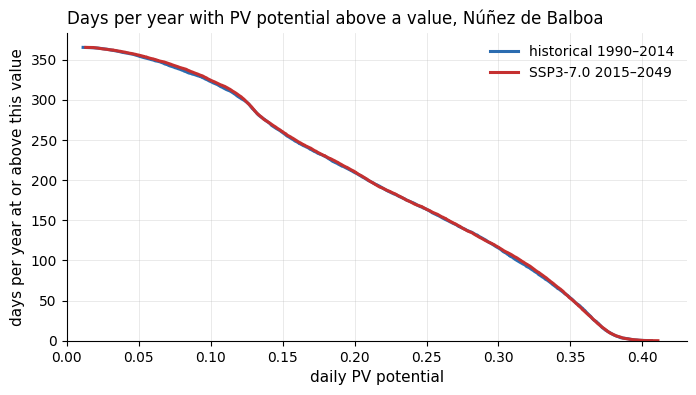

In [28]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_exceedance(ax, pvp, "daily PV potential")
ax.set_title(f"Days per year with PV potential above a value, {site['name']}")
plt.show()

### (f) Map of the surroundings

**Plot only.** PV potential of one summer day around the plant.

*What to look for:* on a clear summer day the differences are small. They come from cloud and from temperature:
panels perform slightly worse where it is hotter.

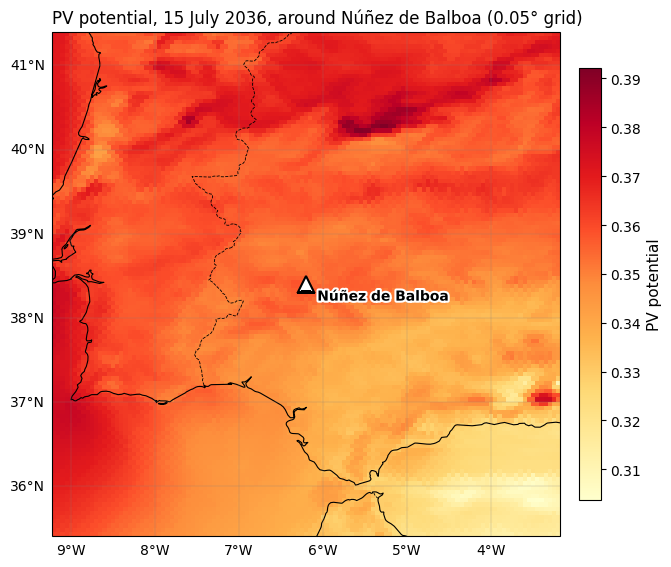

In [29]:
its = month_items(SIMULATIONS["SSP3-7.0"], "2036-07")
href = next(a["href"] for k, a in its[0]["assets"].items() if k.endswith("_15_T00_00_pvp.nc"))
box = read_region(href, access_token, site["lat"], site["lon"])
plot_region(box, "pvp", site, f"PV potential, 15 July 2036, around {site['name']} (0.05° grid)", "YlOrRd", "PV potential")
plt.show()

## Summary

- The Energy Indicators collection holds one item per month and simulation; every indicator is a separate netCDF
  asset on a global 0.05° grid.
- Reading single locations or small regions with HTTP range requests avoids downloading whole files: a few
  kilobytes per file and location.
- Daily indicators (degree days, PV potential) give daily series; wind speed and capacity factor are stored as
  monthly histograms of the hourly values, which give means, annual cycles and distributions.
- The point series read here are kept in `energy_indicators_data/` and can be reused without reading the Data Lake
  again.

This tutorial in the Destination Earth Climate DT use cases repository, next to the tutorials of the other applications: https://github.com/destination-earth-digital-twins/destine-climate-dt-use-cases/blob/main/HDA-REST-quick-start-bsc-and-use.ipynb

More information on the indicators: https://data.destination-earth.eu/data-portfolio/EO.BSC.DAT.ENERGY_INDICATORS

How the indicators are computed, their data description and their quality and evaluation: the Energy Indicators section of the Climate DT user guide, https://platform.destine.eu/services/documents-and-api/doc/?service_name=climate-dt-user-guide

Hourly series are not part of this collection. To compute the indicators yourself from hourly Climate DT fields
(retrieved through Polytope), see the tutorials of the `energy_indicators` package: https://gitlab.earth.bsc.es/digital_twins_public/energy_indicators/-/tree/main/notebooks

## Appendix A. Why conclusions need the whole period

The results above compare the whole historical simulation (1990–2014) with the whole projection (2015–2049).
Comparing only five years of each, as the quick mode does, is enough to learn the method, but too short to draw
conclusions. The reason is natural variability: in the simulation, as in reality, one winter can be much colder than
the next, and a run of a few cold or warm years happens by chance. The average of five years therefore still varies a
lot by chance, while the average of 25–35 years is much more stable. A change between two periods is only meaningful
if it is clearly larger than what chance alone can produce with periods of that length.

The figure shows the heating and cooling degree days in Barcelona for every year from 1990 to 2049, with their
10-year running mean. The shaded bars mark two five-year periods (1990–1994 and 2032–2036). The printed lines below
compare the verdict of the whole period with the verdict you would get from those five years only.

In the full mode this cell uses the series already read. In the quick mode, set `RUN_FULL = True` to read the
degree days for 1990–2049 (about 43,000 files, about one and a half hours on a laptop; kept on disk afterwards).

*What to look for:* how far single years, and even five-year averages, sit from the running mean. The cooling
increase is clear in both comparisons; the heating decrease is clear only over the whole period, because 1990–1994
happens to include two very cold years.

**Computation:** annual sums and their 10-year running mean; the same comparison as in Energy demand (c), once for
the whole periods and once for the five-year periods.

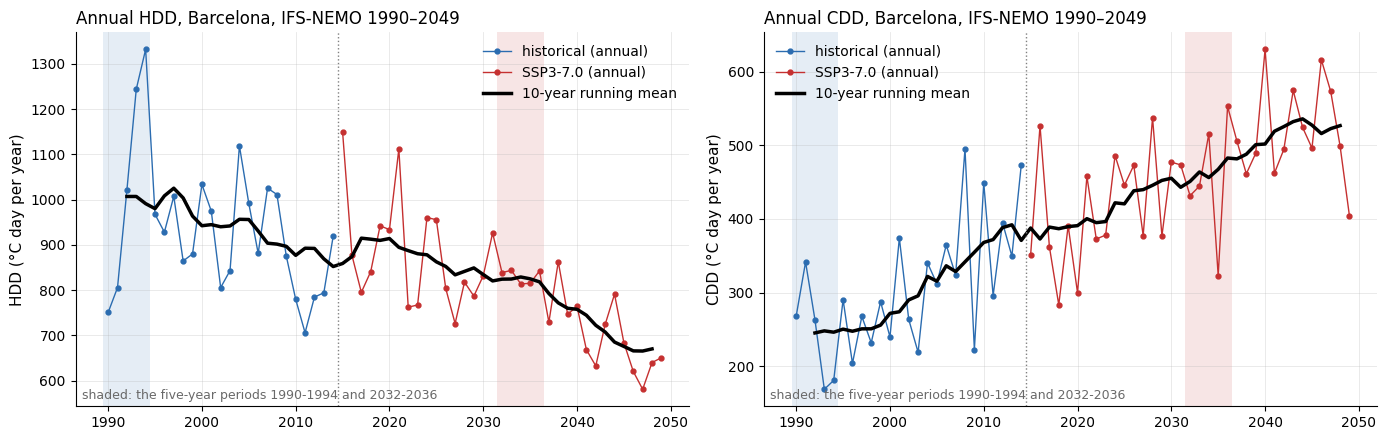

HDD, whole period, 1990-2014 against 2015-2049:


change -127 °C day (-13.6 %): much larger than what the normal differences between years could produce by chance with 25 + 35 complete years, so it is a clear signal (normal year-to-year difference: about 150 °C day)
CDD, whole period, 1990-2014 against 2015-2049:


change +154 °C day (+50.6 %): much larger than what the normal differences between years could produce by chance with 25 + 35 complete years, so it is a clear signal (normal year-to-year difference: about 87 °C day)
HDD, five years only, 1990-1994 against 2032-2036:
change -200 °C day (-19.4 %): larger than what chance usually produces, but not by enough to be sure with 5 + 5 complete years; use 20-30 years per period (normal year-to-year difference: about 258 °C day)
CDD, five years only, 1990-1994 against 2032-2036:
change +209 °C day (+85.6 %): much larger than what the normal differences between years could produce by chance with 5 + 5 complete years, so it is a clear signal (normal year-to-year difference: about 71 °C day)


In [30]:
RUN_FULL = False      # quick mode only: True reads the degree days for 1990-2049 (about 1.5 h)

FIVE = {"historical": (1990, 1994), "SSP3-7.0": (2032, 2036)}
if TUTORIAL_MODE == "full" or RUN_FULL:
    saved = PERIODS
    PERIODS = {"historical": (1990, 2014), "SSP3-7.0": (2015, 2049)}
    site = SITES["demand"]
    whole = {ind: {n: fetch_point_series("demand", n, f"_{ind}.nc")[ind].squeeze() for n in SIMULATIONS}
             for ind in ("hdd", "cdd")}
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for ax, ind in zip(axes, ("hdd", "cdd")):
        parts = {n: annual(da) for n, da in whole[ind].items()}
        for n, (y0, y1) in FIVE.items():
            ax.axvspan(y0 - 0.5, y1 + 0.5, color=COLOURS[n], alpha=0.12, lw=0)
        for n, a in parts.items():
            ax.plot(a.time.dt.year, a, "o-", ms=3.5, color=COLOURS[n], lw=1, label=f"{n} (annual)")
        run10 = xr.concat(list(parts.values()), "time").rolling(time=10, center=True, min_periods=7).mean()
        ax.plot(run10.time.dt.year, run10, color="black", lw=2.5, label="10-year running mean")
        ax.axvline(2014.5, color="grey", lw=1, ls=":")
        ax.annotate("shaded: the five-year periods 1990-1994 and 2032-2036", (0.01, 0.02), xycoords="axes fraction",
                    fontsize=9, color="dimgrey")
        ax.set_ylabel(f"{ind.upper()} (°C day per year)")
        ax.set_title(f"Annual {ind.upper()}, {site['name']}, IFS-NEMO 1990–2049")
        ax.legend(loc="upper right" if ind == "hdd" else "upper left")
    plt.tight_layout()
    plt.show()
    for ind in ("hdd", "cdd"):
        print(f"{ind.upper()}, whole period, 1990-2014 against 2015-2049:")
        compare_to_variability({n: annual(da) for n, da in whole[ind].items()}, "°C day")
    PERIODS = FIVE
    for ind in ("hdd", "cdd"):
        print(f"{ind.upper()}, five years only, 1990-1994 against 2032-2036:")
        compare_to_variability({n: annual(da.sel(time=slice(str(FIVE[n][0]), str(FIVE[n][1]))))
                                for n, da in whole[ind].items()}, "°C day")
    PERIODS = saved
else:
    print("Set RUN_FULL = True, or run the notebook in the full mode, to see this comparison.")

## Appendix B. Setting up a Python environment

The notebook needs Python 3.10 or newer and the packages below. Two ways to create a separate environment:

**With venv and pip**
```bash
python3 -m venv ~/venvs/energy-tutorial
source ~/venvs/energy-tutorial/bin/activate
pip install destinelab requests urllib3 fsspec aiohttp xarray h5netcdf h5py numpy pandas joblib tqdm matplotlib cartopy ipykernel
```

**With conda (or mamba), which installs `cartopy` most reliably**
```bash
conda create -n energy-tutorial -c conda-forge python=3.10 requests urllib3 fsspec aiohttp xarray h5netcdf h5py numpy pandas joblib tqdm matplotlib cartopy ipykernel
conda activate energy-tutorial
pip install destinelab
```

**Use it in Jupyter:** register the environment as a kernel, then choose "energy-tutorial" in the notebook's kernel menu.
```bash
python -m ipykernel install --user --name energy-tutorial --display-name "energy-tutorial"
```

`aiohttp` and `h5netcdf` are needed to read the files remotely; the import cell at the start stops with a clear message
if one of them is missing. Tested with Python 3.10.22, xarray 2025.6.1, h5netcdf 1.8.3, h5py 3.16.0, fsspec 2026.9.0,
aiohttp 3.14.5, numpy 2.2.6, pandas 2.3.3, joblib 1.6.0, matplotlib 3.10.9, cartopy 0.25.0 and destinelab 1.14.